---
title: Week 5 Challenge 3
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about box plots.

Use the notebook **Box Plots** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is `taxis`, available from Seaborn.

It records $6433$ taxi trips taken in New York City in March $2019$.

Each row is an observation for a single trip.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| pickup | Datetime | — | Date and time when the trip began. |
| dropoff | Datetime | — | Date and time when the trip ended. |
| passengers | Integer | 0 – 6 | Number of passengers. |
| distance | Continuous | 0 – 36.7 | Trip distance in miles. |
| fare | Continuous | $1 – $150 | Metered fare in US dollars. |
| tip | Continuous | $0 – $33.2 | Tip amount in US dollars. |
| tolls | Continuous | $0 – $70 | Bridge or tunnel toll charges. |
| total | Continuous | — | Total charge (fare + tip + tolls + surcharges). |
| color | Categorical | yellow, green | Cab color; yellow serves Manhattan and airports, green serves outer boroughs. |
| payment | Categorical | credit card, cash | How the trip was paid. |
| pickup_zone | Categorical | — | Named taxi zone where the trip began. |
| dropoff_zone | Categorical | — | Named taxi zone where the trip ended. |
| pickup_borough | Categorical | Manhattan, Queens, Brooklyn, Bronx, Staten Island | Borough where the trip began. |
| dropoff_borough | Categorical | Manhattan, Queens, Brooklyn, Bronx, Staten Island | Borough where the trip ended. |

## Set Up

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
taxis = sns.load_dataset('taxis')
taxis.index.name = 'trip_id'
taxis.info()
taxis.head()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
trip_id,,,,,,,,,,,,,,
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## Tasks

### Task 1

Create a horizontal box plot of `fare`.

Clean it up so that it does not show an unnecessary bounding box.

Describe the shape of the distribution. Is it symmetric or skewed? Are there visible outliers?

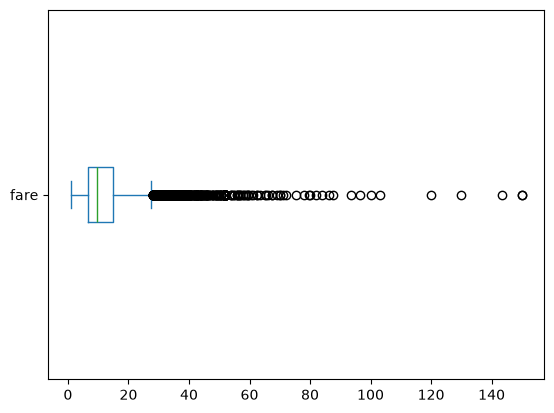

In [9]:
taxis.fare.plot.box(vert=False)
plt.show()

**Answer**: The box plot appears right skewed. There are visible outliers.

### Task 2

Compute $Q1$, $Q3$, the $IQR$, and Tukey's fences for `fare`.

Count how many trips fall outside the fences.

What do you notice about the lower fence?

Hint:
```python
Q1, Q3 = taxis.fare.quantile([.25, .75])
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
```

In [17]:
Q1, Q3 = taxis.fare.quantile([.25, .75])
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

Q1, Q3, IQR, lower, upper

(6.5, 15.0, 8.5, -6.25, 27.75)

**Answer**: 

### Task 3

Compare `fare` across the values of `pickup_borough` by creating a wide table and drawing horizontal box plots sorted by median.

Which borough has the highest median fare?

In [19]:
taxis.fare.median.unstack()

AttributeError: 'function' object has no attribute 'unstack'

**Answer**: 

### Task 4

Every box in the plot from Task 3 is drawn at the same width, regardless of how many trips contributed to it.

How many trips does each borough supply?

Is equal-width boxes a limitation of box plots?

**Answer**: 

### Task 5

Filter the data to trips that began in Queens.

Draw a histogram and a horizontal box plot of `fare` in two panels sharing the same x axis.

What does the histogram reveal that the box plot alone does not?

Hint:
```python
fig, ax = plt.subplots(2, 1, height_ratios=[2, 1], sharex=True)
```

**Answer**: 

### Task 6

The box plots in Task 3 show a cluster of outlier dots near $\$52$ for Manhattan pickups.

What are those trips?

Use the data to investigate your hypothesis.

**Answer**: 

### Bonus

The whiskers in these plots extend using Tukey's $1.5 \times IQR$ rule, which is the default.

Redraw the borough box plots three times — once with the default rule, once with whiskers reaching the full data range, and once at the $5$th and $95$th percentiles.

How does the number of visible outlier points change?

Hint: `.plot.box()` accepts a `whis` argument. It can be a multiplier (e.g. `1.5`) or a pair of percentiles (e.g. `(5, 95)`).